Job Application Assistant: Parallel Multi-Agent Workflow with LangGraph

* Resume Tailor Agent: Customizes your resume for a specific job posting.

* Company Research Agent: Gathers recent company news and crucial job-specific details.

* Their outputs are merged to generate a personalized cover letter draft.



In [1]:
!apt update
!apt install graphviz-dev -y
!pip install langgraph langchain langchain_openai langchain_community tavily-python langgraph-checkpoint-sqlite pygraphviz

Get:1 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:2 https://cli.github.com/packages stable InRelease [3,917 B]
Get:3 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:4 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:5 https://cli.github.com/packages stable/main amd64 Packages [357 B]
Hit:6 http://archive.ubuntu.com/ubuntu noble InRelease
Get:7 http://security.ubuntu.com/ubuntu noble-security/universe amd64 Packages [1,550 kB]
Get:8 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:9 http://security.ubuntu.com/ubuntu noble-security/main amd64 Packages [1,412 kB]
Get:10 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ Packages [75.7 kB]
Get:11 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Get:12 https://r2u.stat.illinois.edu/ubuntu noble/main all Packages [10.5 MB]
Get:13 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:1

In [2]:
import os
from langgraph.graph import StateGraph, END
from typing import TypedDict, List
from langgraph.checkpoint.memory import MemorySaver
memory = MemorySaver()

In [3]:
# Example multiline string simulating a 2-page resume (you can also load a pdf or word doc)
sample_resume = """
Rajesh Kumar
Senior Data Analyst | rajeshk@email.com | 555-123-4567

PROFESSIONAL SUMMARY
Analytical data specialist with 6+ years in FinTech; expert in Python, SQL, Airtable, Tableau. Adept at stakeholder communication and process automation.

WORK EXPERIENCE
ABC Bank, Senior Data Analyst, 2021-2025
- Led ETL pipeline redesign; reduced data lag 30%
- Managed dashboarding for 7 product lines (Power BI & Tableau)
- Mentored junior analysts & project interns

XYZ Analytics, Data Analyst, 2018-2021
- Customer churn model delivered 22% improvement
- Automated weekly reporting pipeline (Python, SQL, Airflow)

EDUCATION
MSc Data Science, Delhi University, 2017

SKILLS
Python, SQL, Tableau, PowerBI, ETL, ML Basics, Stakeholder Reporting, Airflow

PROJECTS
- Fraud detection PoC using Python + scikit-learn
- Automated quarterly reporting tools for ABC’s retail lending

CERTIFICATIONS
- Google Data Analytics
- Tableau Professional

References available upon request.
"""

# sample job description (in real usage, this would come from user paste/upload)
job_description = """
Title: Senior Analytics Specialist – Financial Services

Company: ExampleFinance Inc.

We seek a data-driven analytics pro (5+ years experience) to lead financial modeling projects, automate client reporting, and partner cross-functionally on digital banking initiatives. Requirements:
- Advanced Python & SQL
- Stakeholder-facing dashboards (PowerBI/Tableau)
- Deliver insights for risk/fraud reduction & retention
- Financial services experience required
"""


In [4]:
#Define Agent State
class AgentState(TypedDict):
    resume: str
    job_description: str
    tailored_resume: str
    company_research: str
    cover_letter: str


In [5]:
import os
from getpass import getpass

os.environ["TAVILY_API_KEY"] = getpass(
    "Enter your Tavily API key: "
)

Enter your Tavily API key: ··········


In [6]:
api_key = getpass("Enter your OpenAI API key: ")

os.environ["OPENAI_API_KEY"] = api_key

Enter your OpenAI API key: ··········


In [7]:
# Initialize OpenAI LLM
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(
    model="gpt-4o",
    temperature=0
)

# Initialize Tavily client
from tavily import TavilyClient

tavily = TavilyClient(
    api_key=os.environ["TAVILY_API_KEY"]
)

* Define Agent Nodes

In [8]:
#Resume Tailor Agent
def tailor_resume_node(state: AgentState):
    prompt = f"""You are a resume consultant. Tailor the following resume for this specific job description. Highlight directly relevant experience, and trim less relevant sections to fit a 2-page limit.

Job Description:
{state['job_description']}

Resume:
{state['resume']}

Return the improved resume.
"""
    result = llm.invoke([{"role": "user", "content": prompt}])
    return {"tailored_resume": result.content}


* Company Research Agent

In [9]:
#Let us use Tavily to fetch latest news and job-relevant insights
def company_research_node(state: AgentState):
    prompt = f"""Find 2-3 key recent news items or major facts about '{state['job_description'].split('Company: ')[-1].split()[0]}'. Focus on company growth, strategy, financial health, or culture.
Also, list 2 top requirements/keywords from the job description.

Job Posting:
{state['job_description']}
"""
    # LLM suggests research queries
    queries = llm.invoke([{"role": "user", "content": f"Suggest two research queries for {prompt}"}]).content.split('\n')
    research_content = []
    for q in queries:
        if q.strip():
            response = tavily.search(query=q, max_results=2)
            research_content.extend([r['content'] for r in response['results']])
    return {"company_research": "\n".join(research_content[:3])}


* Merge Agent Outputs to Draft Cover Letter

In [10]:
def draft_cover_letter_node(state: AgentState):
    prompt = f"""You are a career advisor. Using the tailored resume and company research below, generate a concise but personalized cover letter for the specified position. Make sure to mention recent company news (if positive), and clearly link your skills/achievements to the requirements.

Job Description:
{state['job_description']}

Tailored Resume (condensed):
{state['tailored_resume']}

Company News/Research:
{state['company_research']}

Return only the cover letter.
"""
    result = llm.invoke([{"role": "user", "content": prompt}])
    return {"cover_letter": result.content}


* Building a Parallel LangGraph Workflow

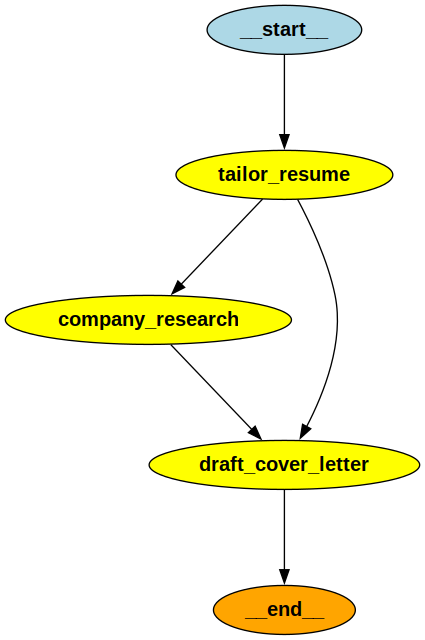

In [11]:
builder = StateGraph(AgentState)
# Add parallel nodes
builder.add_node("tailor_resume", tailor_resume_node)
builder.add_node("company_research", company_research_node)
# Add merging node
builder.add_node("draft_cover_letter", draft_cover_letter_node)

# Parallel edges from entry to both workers
builder.set_entry_point("tailor_resume")

builder.add_edge("tailor_resume", "company_research")
builder.add_edge(["tailor_resume", "company_research"], "draft_cover_letter")

builder.add_edge("draft_cover_letter", END)
graph = builder.compile(checkpointer=memory)
from IPython.display import Image
Image(graph.get_graph().draw_png())


In [12]:
thread = {"configurable": {"thread_id": "job1"}}
input_state = {
    "resume": sample_resume,
    "job_description": job_description
}
for update in graph.stream(input_state, thread):
    print(update)
    # Extract and store final results as needed


{'tailor_resume': {'tailored_resume': 'Rajesh Kumar  \nSenior Data Analyst  \nrajeshk@email.com | 555-123-4567  \n\n---\n\n**PROFESSIONAL SUMMARY**  \nAnalytical data specialist with over 6 years of experience in financial services, specializing in Python, SQL, and Tableau. Proven track record in leading financial modeling projects, automating client reporting, and delivering insights for risk and fraud reduction. Strong communicator adept at stakeholder engagement and cross-functional collaboration.\n\n---\n\n**WORK EXPERIENCE**  \n\n**ABC Bank**  \n*Senior Data Analyst*  \n2021-2025  \n\n- Led financial modeling projects, enhancing decision-making processes and reducing risk exposure.\n- Managed and developed stakeholder-facing dashboards for 7 product lines using Power BI and Tableau, improving data accessibility and insights delivery.\n- Automated client reporting processes, significantly increasing efficiency and accuracy.\n- Mentored junior analysts and project interns, fostering

In [13]:
!pip install python-docx


In [14]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [15]:
from docx import Document
import os

def save_to_word(text, filepath):
    doc = Document()
    doc.add_paragraph(text)
    doc.save(filepath)
    print(f"File saved to: {filepath}")


In [16]:
# Set your Google Drive folder path here (change 'My Drive/JobApplications' as needed)
folder_path = '/content/drive/My Drive/DL'
os.makedirs(folder_path, exist_ok=True)

# file paths
resume_path = os.path.join(folder_path, 'Tailored_Resume2.docx')
cover_letter_path = os.path.join(folder_path, 'Cover_Letter2.docx')


final_result = graph.invoke(input_state, thread)

final_state = {"tailored_resume": final_result["tailored_resume"],"cover_letter": final_result["cover_letter"]
}

# Save the Word documents
save_to_word(final_state["tailored_resume"], resume_path)
save_to_word(final_state["cover_letter"], cover_letter_path)


File saved to: /content/drive/My Drive/DL/Tailored_Resume2.docx
File saved to: /content/drive/My Drive/DL/Cover_Letter2.docx
